# Step-by-step implementation of Adaboost

- Let's take a classification problem to understand :

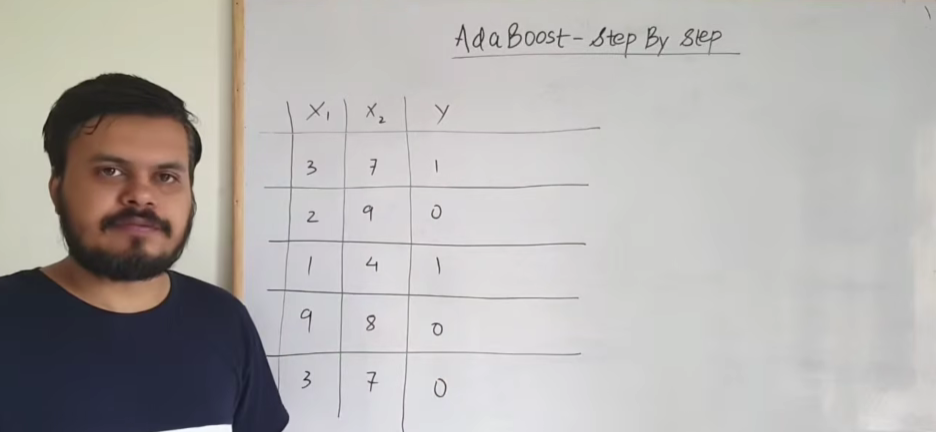

## Steps:

##### 1. Initialize the weights of all the training samples to be equal. So, if we have N training samples, then the weight of each sample will be 1/N.

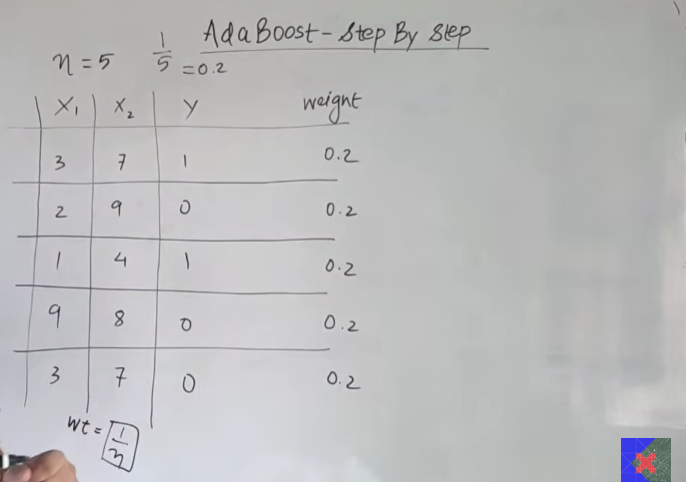

##### 2. Now we will go to Stage 1

- Train the first desicion stump ($m_1$) on the training data with equal weights.
- Now predict the labels of the training data ($Y_{pred}$) using the trained model ($m_1$)
    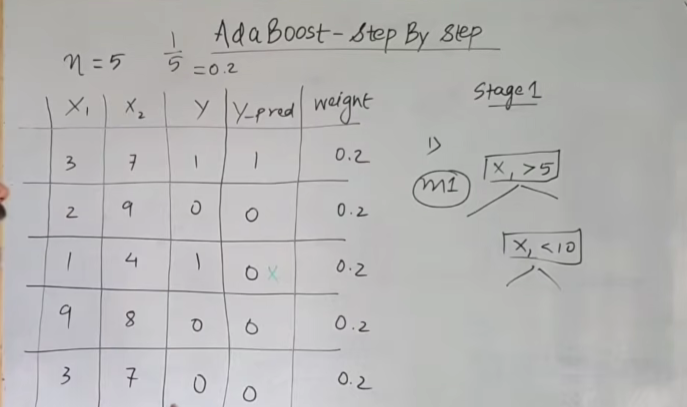

- Now calculate $\alpha_1$ based on the accuracy of the first weak learner. $\alpha_1$ is a measure of the strength of the weak learner in the final ensemble.
    -  $\alpha_1$ depends on the error rate of the weak learner. The lower the error rate, the higher the $\alpha_1$ value and vice-versa.

    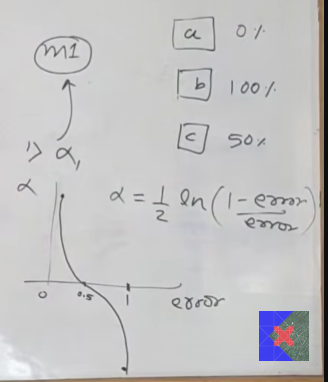

    - In the pic you can see, error rate = 0% (will have highest +ve $\alpha_1$)  and error rate = 100% (will have lowest -ve $\alpha_1$, i.e just take the opposite of what the model predicts) are the most reliable weak learner (magnitude wise) and error rate = 50% is the least reliable weak learner.

    - $$ \alpha_1 = \frac{1}{2} \ln(\frac{1 - error}{error}) $$

    - Error rate = ${sum(weights of misclassified samples)}$

        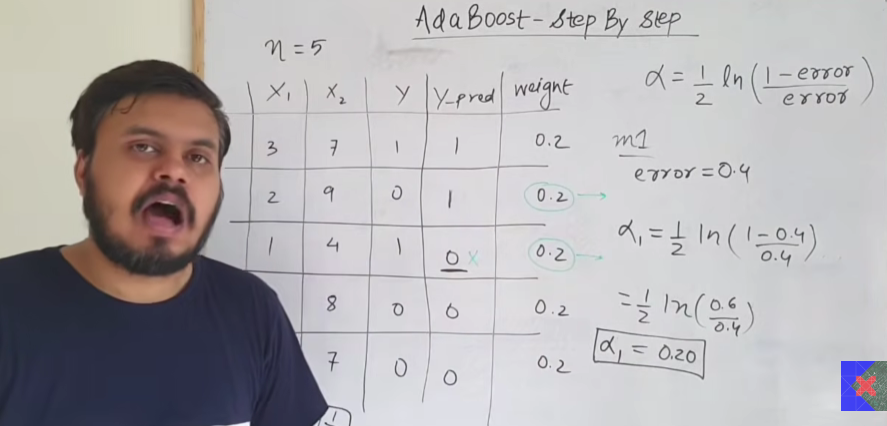

- Now before going to the next stage, we need to increase/**boost** the weights of the misclassified samples and decrease the weights of the correctly classified samples. This is done so that in the next stage, the weak learner will focus more on the misclassified samples.

    - $w_{i,new} = w_{i,curr} \times e^{\alpha_1}$ if sample $i$ is misclassified
    - $w_{i,new} = w_{i,curr} \times e^{-\alpha_1}$ if sample $i$ is correctly classified

    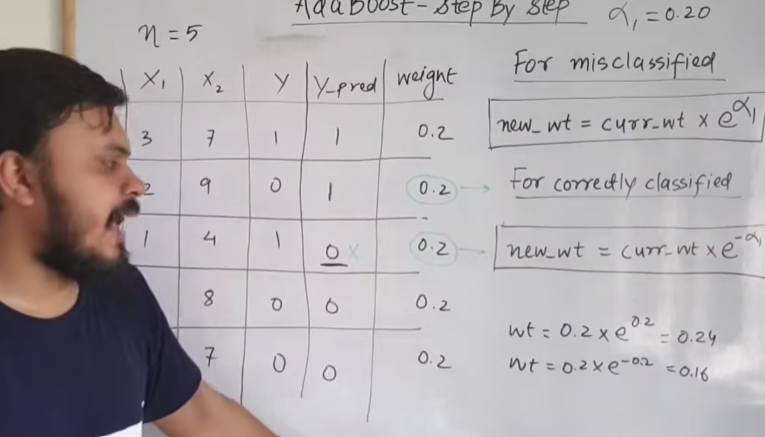


- Now we need to normalize the weights so that they sum to 1. This is done by dividing each weight by the sum of all weights.

    - $$ w_{i} = \frac{w_{i}}{sum(w)} $$

    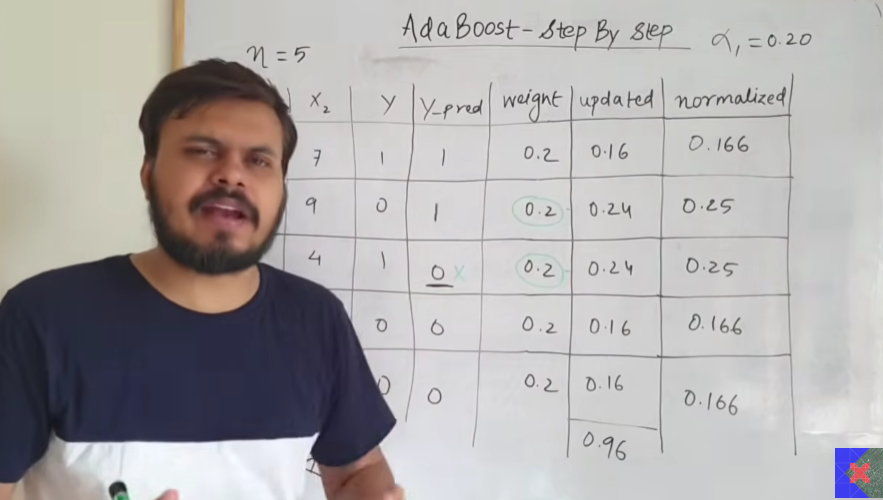

##### 3. Upsampling (before going to next stage)

- Create a new dataset, where we define range of each sample based on its weight. The **higher the weight, the larger the range of the sample**.
      - This is done so that when we randomly select samples for the next stage, the samples with higher weights have a higher chance of being selected.
      - For example, if we have 3 samples with weights 0.1, 0.2 and 0.7, then we can define the range of each sample as follows:
        - Sample 1: [0, 0.1)
        - Sample 2: [0.1, 0.3)
        - Sample 3: [0.3, 1)

- Now generate a random number between 0 and 1 and select the sample whose range contains the random number. Repeat this process until we have N samples in the new dataset.

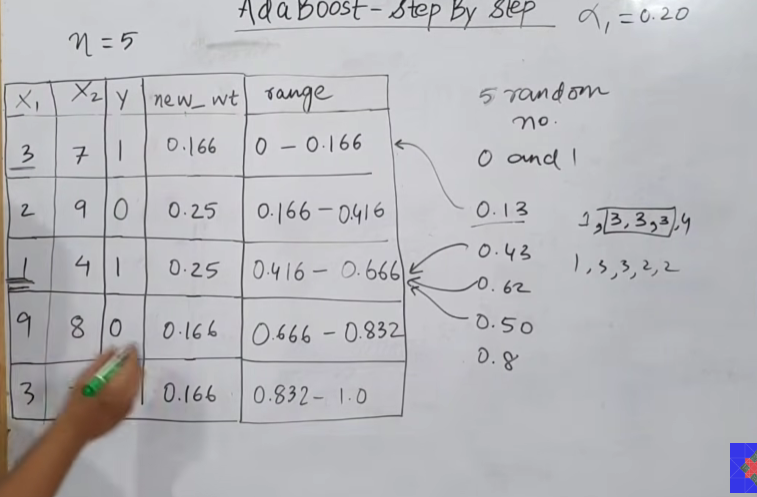

##### 4. Now we will go to Stage 2

- Here we will train the second desicion stump ($m_2$) on the new dataset (upsampled dataset, that has the samples we got from step 3) and repeat the same process as in Stage 1.
  

See the [code](3-Adaboost_demo.ipynb) for the implementation of the above steps.

### The reason behind multiplying exponentials to update weight:

- As the input to the exponential function is $\alpha_1$ which is a measure of the strength of the weak learner, so if the weak learner is strong (i.e. has low error rate so $\alpha_1$ vlaue will be high), then the weight of the misclassified samples will be **increased more** and the weight of the correctly classified samples will be **decreased more** and vice-versa

- This is because, as $\alpha_1$ is high, we can trust the weak learner more and so we can increase/decrease the weights of the samples more. And if $\alpha_1$ is low, we can trust the weak learner less and so we can increase/decrease the weights of the samples less.

# Prediction:

- For 3 models, the final prediction will be: 1 ,0,0
- Then convert the predictions to +1 and -1, so the final prediction will be: +1, -1, -1

- Final prediction = sign($\alpha_1$ * 1 + $\alpha_2$ * (-1) + $\alpha_3$ * (-1)) = sign($\alpha_1$ - $\alpha_2$ - $\alpha_3$)

- If the final prediction is +ve, then the final class label will be 1 and if the final prediction is -ve, then the final class label will be 0.